# Deep CSI Dataset Analysis ? WiCount

Analisis deskriptif mencakup **seluruh rekaman CSV** di arsip WiCount asli. Data ZIP dibaca langsung tanpa ekstraksi/perubahan. Tidak ada model Machine Learning yang dilatih. Unit sesi untuk analisis adalah satu file CSV; label okupansi mengikuti folder sumber.

## 1. Environment and source integrity

Muat library yang sudah tercantum di `analysis/requirements.txt`, temukan root proyek relatif terhadap working directory, dan pastikan dataset asli tersedia.

In [1]:
from pathlib import Path, PurePosixPath
from collections import Counter
import json
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy

candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
PROJECT_ROOT = next(
    (path for path in candidates if (path / "PRD.md").is_file() and (path / "analysis").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate WiFiSENSE project root from notebook working directory")

DATASET_ZIP = PROJECT_ROOT / "analysis" / "dataset" / "WiCount" / "WiCount.zip"
OUTPUT_DIR = PROJECT_ROOT / "analysis" / "outputs"
if not DATASET_ZIP.is_file():
    raise FileNotFoundError(f"Original WiCount archive not found: {DATASET_ZIP}")

EXPECTED_COMPONENTS = 104
EXPECTED_SUBCARRIERS = EXPECTED_COMPONENTS // 2
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Archive: {DATASET_ZIP.relative_to(PROJECT_ROOT)} ({DATASET_ZIP.stat().st_size:,} bytes)")
print(f"Python analysis: NumPy {np.__version__}, pandas {pd.__version__}, SciPy {scipy.__version__}")

Archive: analysis\dataset\WiCount\WiCount.zip (9,389,189 bytes)
Python analysis: NumPy 2.5.2, pandas 3.0.5, SciPy 1.18.1


## 2. Read and validate all recordings

CSV files are streamed from the ZIP. Each `data` payload is checked as a JSON list of exactly 104 finite numeric components and reshaped into 52 adjacent real/imaginary pairs according to the verified WiCount description. CSI amplitude is `hypot(real, imaginary)`. Invalid payloads and timestamp/sequence anomalies are counted, not silently imputed.

In [2]:
def parse_csi_amplitude(payload):
    values = json.loads(payload) if isinstance(payload, str) else payload
    if not isinstance(values, list):
        raise ValueError("payload is not a JSON list")
    if len(values) != EXPECTED_COMPONENTS:
        raise ValueError(f"expected {EXPECTED_COMPONENTS} components, found {len(values)}")
    if any(isinstance(v, bool) or not isinstance(v, (int, float)) for v in values):
        raise ValueError("payload has a non-numeric component")
    components = np.asarray(values, dtype=np.float64)
    if not np.isfinite(components).all():
        raise ValueError("payload has a non-finite component")
    pairs = components.reshape(EXPECTED_SUBCARRIERS, 2)
    return np.hypot(pairs[:, 0], pairs[:, 1])


def describe_amplitude(values):
    flat = np.asarray(values, dtype=np.float64).ravel()
    if flat.size == 0:
        return {key: np.nan for key in ["mean", "median", "std", "variance", "min", "max", "q1", "q3", "iqr"]}
    q1, median, q3 = np.quantile(flat, [0.25, 0.50, 0.75])
    return {
        "mean": float(np.mean(flat)),
        "median": float(median),
        "std": float(np.std(flat, ddof=1)) if flat.size > 1 else 0.0,
        "variance": float(np.var(flat, ddof=1)) if flat.size > 1 else 0.0,
        "min": float(np.min(flat)),
        "max": float(np.max(flat)),
        "q1": float(q1),
        "q3": float(q3),
        "iqr": float(q3 - q1),
    }


with zipfile.ZipFile(DATASET_ZIP) as archive:
    csv_members = sorted(
        name for name in archive.namelist()
        if name.lower().endswith(".csv")
        and len(PurePosixPath(name).parts) == 3
        and PurePosixPath(name).parts[0] == "data"
        and PurePosixPath(name).parts[1] in {"0", "1", "2", "3"}
    )
    if not csv_members:
        raise ValueError("No recordings found at data/<occupancy>/*.csv in archive")

    recordings = {}
    recording_rows = []
    validation_issues = []
    schema_by_file = {}

    for member in csv_members:
        label = int(PurePosixPath(member).parts[1])
        with archive.open(member) as csv_stream:
            frame = pd.read_csv(csv_stream, usecols=["type", "seq", "timestamp", "local_timestamp", "rssi", "len", "first_word_invalid", "data"])
        schema_by_file[member] = tuple(frame.columns)
        amplitudes = []
        valid_row_indices = []
        invalid_payload_count = 0
        len_mismatch_count = 0
        for row_index, row in enumerate(frame.itertuples(index=False)):
            try:
                amplitude = parse_csi_amplitude(row.data)
                if pd.isna(row.len) or int(row.len) != EXPECTED_COMPONENTS:
                    len_mismatch_count += 1
                    validation_issues.append({"file": member, "row": row_index, "issue": "len field differs from 104"})
                amplitudes.append(amplitude)
                valid_row_indices.append(row_index)
            except (ValueError, TypeError, json.JSONDecodeError) as error:
                invalid_payload_count += 1
                validation_issues.append({"file": member, "row": row_index, "issue": str(error)})

        valid_frame = frame.iloc[valid_row_indices].reset_index(drop=True)
        amplitude_matrix = np.stack(amplitudes) if amplitudes else np.empty((0, EXPECTED_SUBCARRIERS))
        parsed_times = pd.to_datetime(valid_frame["timestamp"], errors="coerce")
        valid_time_mask = parsed_times.notna().to_numpy()
        time_ns = parsed_times[valid_time_mask].astype("int64").to_numpy()
        deltas_seconds = np.diff(time_ns) / 1e9
        positive_deltas = deltas_seconds[deltas_seconds > 0]
        sequence = pd.to_numeric(valid_frame["seq"], errors="coerce").to_numpy(dtype=np.float64)
        sequence_deltas = np.diff(sequence[np.isfinite(sequence)])
        rssi = pd.to_numeric(valid_frame["rssi"], errors="coerce").to_numpy(dtype=np.float64)
        first_word_invalid = pd.to_numeric(valid_frame["first_word_invalid"], errors="coerce").to_numpy(dtype=np.float64)

        stats = describe_amplitude(amplitude_matrix)
        start_time = parsed_times.min()
        end_time = parsed_times.max()
        duration_seconds = float((end_time - start_time).total_seconds()) if pd.notna(start_time) and pd.notna(end_time) else np.nan
        row_info = {
            "occupancy": label,
            "file": member,
            "recording": PurePosixPath(member).name,
            "rows": len(frame),
            "valid_csi_rows": len(amplitude_matrix),
            "invalid_payload_rows": invalid_payload_count,
            "len_mismatch_rows": len_mismatch_count,
            "timestamp_invalid_rows": int((~valid_time_mask).sum()),
            "timestamp_start": start_time,
            "timestamp_end": end_time,
            "duration_seconds": duration_seconds,
            "timestamp_duplicate_intervals": int(np.count_nonzero(deltas_seconds == 0)),
            "timestamp_backwards_intervals": int(np.count_nonzero(deltas_seconds < 0)),
            "positive_interval_median_ms": float(np.median(positive_deltas) * 1000) if positive_deltas.size else np.nan,
            "positive_interval_p95_ms": float(np.quantile(positive_deltas, 0.95) * 1000) if positive_deltas.size else np.nan,
            "sequence_nonconsecutive_intervals": int(np.count_nonzero(sequence_deltas != 1)),
            "sequence_backwards_intervals": int(np.count_nonzero(sequence_deltas < 0)),
            "rssi_invalid_rows": int((~np.isfinite(rssi)).sum()),
            "rssi_min": float(np.nanmin(rssi)) if np.isfinite(rssi).any() else np.nan,
            "rssi_max": float(np.nanmax(rssi)) if np.isfinite(rssi).any() else np.nan,
            "first_word_invalid_nonzero_rows": int(np.count_nonzero(first_word_invalid == 1)),
            **{f"amp_{key}": value for key, value in stats.items()},
        }
        recording_rows.append(row_info)
        recordings[member] = {
            "occupancy": label,
            "frame": valid_frame,
            "amplitude": amplitude_matrix,
            "timestamps": parsed_times,
        }

recording_stats = pd.DataFrame(recording_rows).sort_values(["occupancy", "file"]).reset_index(drop=True)
if len(recording_stats) != 15:
    raise ValueError(f"Expected 15 CSV recordings, found {len(recording_stats)}")
print(f"CSV recordings audited: {len(recording_stats)}")
print(f"CSI records: {int(recording_stats['rows'].sum()):,}")
print(f"Parsed amplitude values: {int(recording_stats['valid_csi_rows'].sum() * EXPECTED_SUBCARRIERS):,}")
print(f"Invalid CSI payload rows: {int(recording_stats['invalid_payload_rows'].sum())}")
print(f"Timestamp parse failures: {int(recording_stats['timestamp_invalid_rows'].sum())}")
display(recording_stats[["occupancy", "recording", "rows", "valid_csi_rows", "duration_seconds", "positive_interval_median_ms", "timestamp_duplicate_intervals", "timestamp_backwards_intervals", "sequence_nonconsecutive_intervals", "invalid_payload_rows"]])

CSV recordings audited: 15
CSI records: 78,618
Parsed amplitude values: 4,088,136
Invalid CSI payload rows: 0
Timestamp parse failures: 0


,occupancy,recording,rows,valid_csi_rows,duration_seconds,positive_interval_median_ms,timestamp_duplicate_intervals,timestamp_backwards_intervals,sequence_nonconsecutive_intervals,invalid_payload_rows
0,0,2023-12-21_19-23-53-985_104_1.csv,5218,5218,59.985,0.016,1341,0,0,0
1,1,2023-12-21_19-27-21-930_104_1.csv,4780,4780,59.993,0.016,845,0,0,0
2,1,2023-12-21_19-31-17-706_104_1.csv,5189,5189,60.004,0.016,993,0,0,0
3,1,2023-12-21_19-34-42-783_104_1.csv,5234,5234,59.997,0.012,182,0,0,0
4,1,2023-12-21_19-37-36-861_104_1.csv,5163,5163,59.985,0.015,952,0,0,0
5,1,2023-12-21_19-40-12-110_104_1.csv,5421,5421,59.980,0.015,1147,0,0,0
6,1,2023-12-21_19-42-28-267_104_1.csv,5644,5644,59.975,0.015,1264,0,0,0
7,1,2023-12-21_19-45-07-501_104_1.csv,5128,5128,59.994,0.012,359,0,0,0
8,2,2023-12-21_19-47-14-669_104_1.csv,5376,5376,59.988,0.011,0,0,0,0
9,2,2023-12-21_19-49-37-940_104_1.csv,5307,5307,59.986,0.015,1073,0,0,0


## 3. Amplitude statistics by recording and occupancy class

Statistics describe every valid amplitude observation, pooled across 52 subcarriers and all rows within the relevant recording/class. `std` and `variance` are sample estimates (`ddof=1`); IQR is Q3?Q1. Class-pool values are row-weighted because longer files contribute more records, so session-level comparisons are also shown separately.

In [3]:
class_rows = []
class_amplitudes = {}
for occupancy in [0, 1, 2, 3]:
    members = [member for member in recordings if recordings[member]["occupancy"] == occupancy]
    matrices = [recordings[member]["amplitude"] for member in members]
    values = np.concatenate([matrix.ravel() for matrix in matrices]) if matrices else np.array([], dtype=float)
    class_amplitudes[occupancy] = values
    class_rows.append({
        "occupancy": occupancy,
        "recordings": len(members),
        "records": int(sum(len(recordings[member]["frame"]) for member in members)),
        "amplitude_observations": int(values.size),
        **describe_amplitude(values),
    })
class_stats = pd.DataFrame(class_rows)
recording_count_by_class = recording_stats.groupby("occupancy").size().reindex([0, 1, 2, 3], fill_value=0)
record_count_by_class = recording_stats.groupby("occupancy")["rows"].sum().reindex([0, 1, 2, 3], fill_value=0)
class_balance = pd.DataFrame({"recordings": recording_count_by_class, "CSI_records": record_count_by_class})
class_balance["recording_share"] = class_balance["recordings"] / class_balance["recordings"].sum()
class_balance["record_share"] = class_balance["CSI_records"] / class_balance["CSI_records"].sum()
print("Recording and row balance by occupancy folder:")
display(class_balance)
print("Pooled amplitude statistics by class:")
display(class_stats)
print("Per-recording amplitude statistics:")
display(recording_stats[["occupancy", "recording", "amp_mean", "amp_median", "amp_std", "amp_variance", "amp_min", "amp_max", "amp_q1", "amp_q3", "amp_iqr"]])

Recording and row balance by occupancy folder:


,recordings,CSI_records,recording_share,record_share
occupancy,,,,
0,1,5218,0.066667,0.066372
1,7,36559,0.466667,0.465021
2,6,31935,0.400000,0.406205
3,1,4906,0.066667,0.062403


Pooled amplitude statistics by class:


,occupancy,recordings,records,amplitude_observations,mean,median,std,variance,min,max,q1,q3,iqr
0,0,1,5218,271336,14.312227,13.341664,5.458830,29.798823,2.236068,30.265492,10.198039,17.492856,7.294817
1,1,7,36559,1901068,14.043041,13.038405,5.799323,33.632144,0.000000,36.878178,9.848858,17.691806,7.842948
2,2,6,31935,1660620,13.595434,12.529964,5.958517,35.503926,0.000000,36.769553,9.219544,17.492856,8.273311
3,3,1,4906,255112,13.549148,12.806248,5.796828,33.603212,0.000000,36.345564,9.219544,17.492856,8.273311


Per-recording amplitude statistics:


,occupancy,recording,amp_mean,amp_median,amp_std,amp_variance,amp_min,amp_max,amp_q1,amp_q3,amp_iqr
0,0,2023-12-21_19-23-53-985_104_1.csv,14.312227,13.341664,5.458830,29.798823,2.236068,30.265492,10.198039,17.492856,7.294817
1,1,2023-12-21_19-27-21-930_104_1.csv,14.157426,13.152946,5.875187,34.517823,0.000000,36.400549,9.899495,17.804494,7.904999
2,1,2023-12-21_19-31-17-706_104_1.csv,14.176332,13.152946,5.595092,31.305052,0.000000,36.055513,10.049876,17.262677,7.212801
3,1,2023-12-21_19-34-42-783_104_1.csv,14.099789,13.038405,5.955038,35.462474,0.000000,36.769553,9.848858,18.000000,8.151142
4,1,2023-12-21_19-37-36-861_104_1.csv,14.126396,13.038405,5.826003,33.942311,0.000000,36.359318,9.899495,17.804494,7.904999
5,1,2023-12-21_19-40-12-110_104_1.csv,13.954571,13.000000,5.725698,32.783621,0.000000,33.241540,9.848858,17.464249,7.615391
6,1,2023-12-21_19-42-28-267_104_1.csv,13.932225,12.806248,5.776377,33.366526,0.000000,34.669872,9.486833,17.804494,8.317661
7,1,2023-12-21_19-45-07-501_104_1.csv,13.875190,12.806248,5.837858,34.080583,0.000000,36.878178,9.486833,17.691806,8.204973
8,2,2023-12-21_19-47-14-669_104_1.csv,13.463463,12.727922,5.846803,34.185109,0.000000,35.608988,9.219544,17.088007,7.868463
9,2,2023-12-21_19-49-37-940_104_1.csv,13.620078,12.649111,6.434861,41.407433,0.000000,36.400549,9.000000,17.804494,8.804494


## 4. Timestamp, sequence, and payload quality

Timestamp intervals are computed in CSV row order. Equal timestamps are reported separately from backwards timestamps; they are not treated as invalid CSI payloads. Positive intervals are summarized without converting the source timestamps to an assumed sampling clock. `seq` discontinuities, `len` mismatches, and the source `first_word_invalid` flag are reported independently.

In [4]:
time_summary = recording_stats[[
    "occupancy", "recording", "rows", "timestamp_start", "timestamp_end", "duration_seconds",
    "positive_interval_median_ms", "positive_interval_p95_ms", "timestamp_duplicate_intervals",
    "timestamp_backwards_intervals", "sequence_nonconsecutive_intervals", "sequence_backwards_intervals",
    "timestamp_invalid_rows", "rssi_invalid_rows", "first_word_invalid_nonzero_rows",
    "invalid_payload_rows", "len_mismatch_rows",
]].copy()
display(time_summary)
print(f"Total duplicate timestamp intervals: {int(recording_stats['timestamp_duplicate_intervals'].sum()):,}")
print(f"Total backwards timestamp intervals: {int(recording_stats['timestamp_backwards_intervals'].sum()):,}")
print(f"Total nonconsecutive seq intervals: {int(recording_stats['sequence_nonconsecutive_intervals'].sum()):,}")
print(f"Total source first_word_invalid flags: {int(recording_stats['first_word_invalid_nonzero_rows'].sum()):,}")
print(f"Payload validation issue rows: {len(validation_issues):,}")
if validation_issues:
    display(pd.DataFrame(validation_issues).head(20))

,occupancy,recording,rows,timestamp_start,timestamp_end,duration_seconds,positive_interval_median_ms,positive_interval_p95_ms,timestamp_duplicate_intervals,timestamp_backwards_intervals,sequence_nonconsecutive_intervals,sequence_backwards_intervals,timestamp_invalid_rows,rssi_invalid_rows,first_word_invalid_nonzero_rows,invalid_payload_rows,len_mismatch_rows
0,0,2023-12-21_19-23-53-985_104_1.csv,5218,2023-12-21 19:23:53.985,2023-12-21 19:24:53.970,59.985,0.016,0.021,1341,0,0,0,0,0,0,0,0
1,1,2023-12-21_19-27-21-930_104_1.csv,4780,2023-12-21 19:27:21.930,2023-12-21 19:28:21.923,59.993,0.016,0.030,845,0,0,0,0,0,0,0,0
2,1,2023-12-21_19-31-17-706_104_1.csv,5189,2023-12-21 19:31:17.706,2023-12-21 19:32:17.710,60.004,0.016,0.023,993,0,0,0,0,0,0,0,0
3,1,2023-12-21_19-34-42-783_104_1.csv,5234,2023-12-21 19:34:42.783,2023-12-21 19:35:42.780,59.997,0.012,0.020,182,0,0,0,0,0,0,0,0
4,1,2023-12-21_19-37-36-861_104_1.csv,5163,2023-12-21 19:37:36.861,2023-12-21 19:38:36.846,59.985,0.015,0.024,952,0,0,0,0,0,0,0,0
5,1,2023-12-21_19-40-12-110_104_1.csv,5421,2023-12-21 19:40:12.110,2023-12-21 19:41:12.090,59.980,0.015,0.022,1147,0,0,0,0,0,0,0,0
6,1,2023-12-21_19-42-28-267_104_1.csv,5644,2023-12-21 19:42:28.267,2023-12-21 19:43:28.242,59.975,0.015,0.021,1264,0,0,0,0,0,0,0,0
7,1,2023-12-21_19-45-07-501_104_1.csv,5128,2023-12-21 19:45:07.501,2023-12-21 19:46:07.495,59.994,0.012,0.020,359,0,0,0,0,0,0,0,0
8,2,2023-12-21_19-47-14-669_104_1.csv,5376,2023-12-21 19:47:14.669,2023-12-21 19:48:14.657,59.988,0.011,0.017,0,0,0,0,0,0,0,0,0
9,2,2023-12-21_19-49-37-940_104_1.csv,5307,2023-12-21 19:49:37.940,2023-12-21 19:50:37.926,59.986,0.015,0.023,1073,0,0,0,0,0,0,0,0


Total duplicate timestamp intervals: 8,900
Total backwards timestamp intervals: 0
Total nonconsecutive seq intervals: 0
Total source first_word_invalid flags: 0
Payload validation issue rows: 0


## 5. Amplitude comparison across all recordings

Each box summarizes the full amplitude distribution from one recording, preserving session identity. Class distributions pool valid amplitudes from all files in that folder and are normalized for visual shape comparison; sample counts differ substantially.

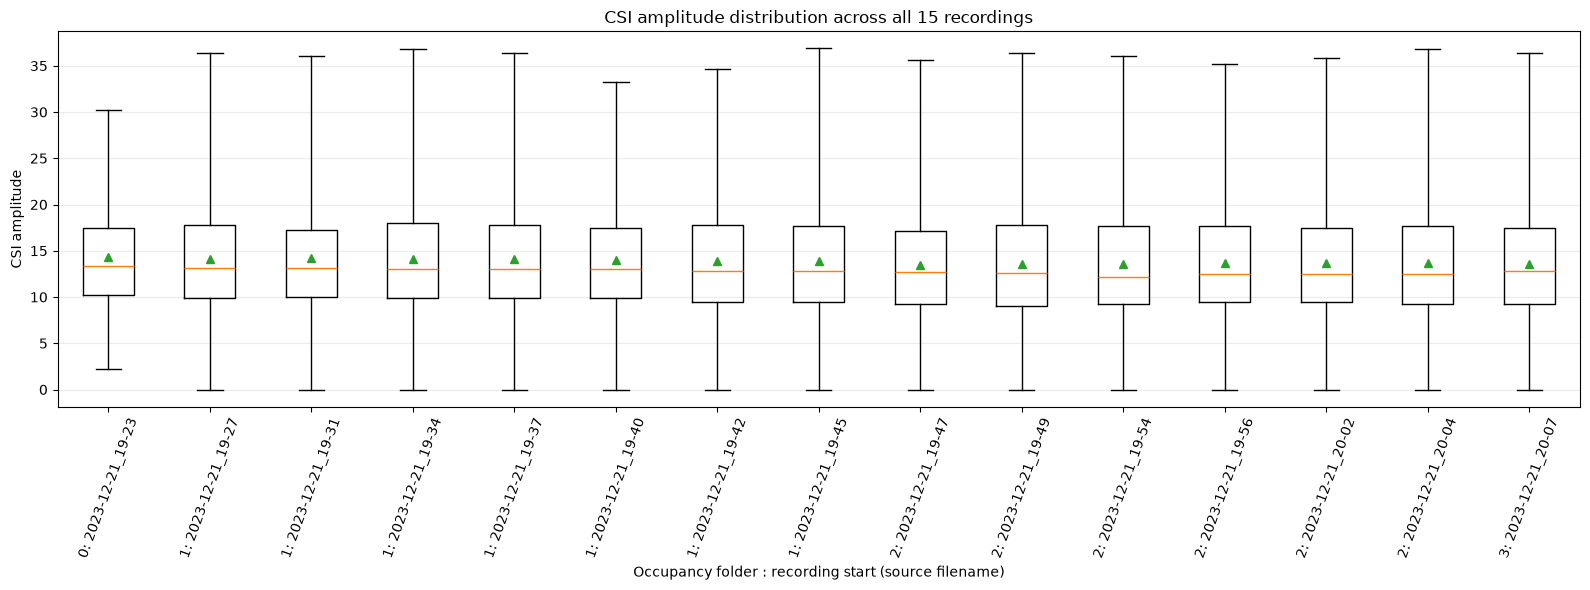

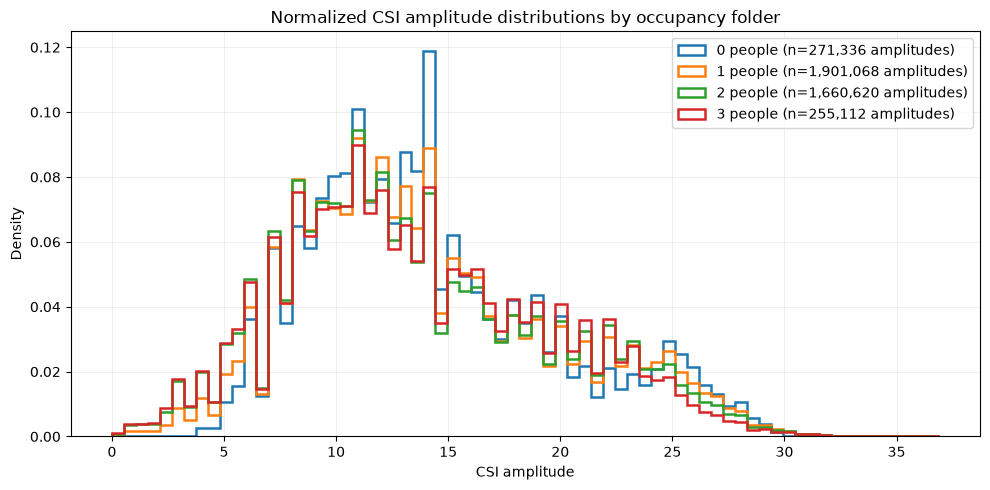

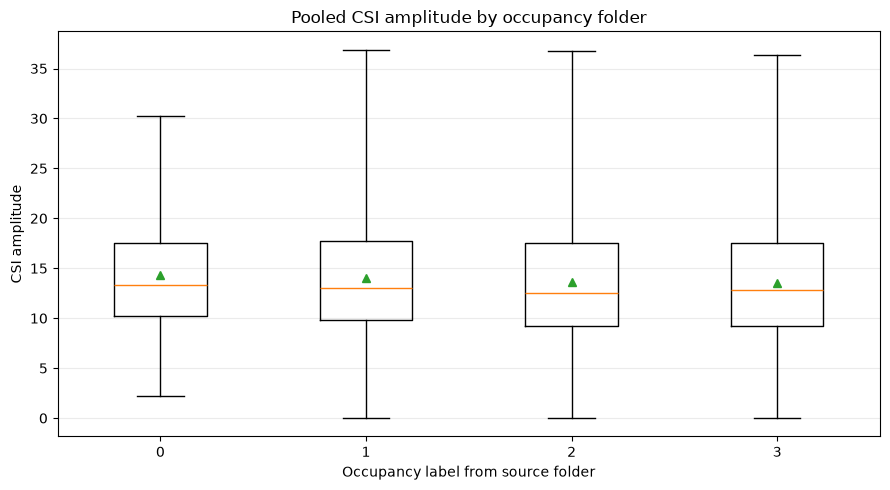

In [5]:
fig, ax = plt.subplots(figsize=(16, 6))
bxp = []
for row in recording_stats.itertuples(index=False):
    bxp.append({
        "label": f"{row.occupancy}: {row.recording[:16]}",
        "whislo": row.amp_min,
        "q1": row.amp_q1,
        "med": row.amp_median,
        "q3": row.amp_q3,
        "whishi": row.amp_max,
        "mean": row.amp_mean,
        "fliers": [],
    })
ax.bxp(bxp, showfliers=False, showmeans=True, meanline=False)
ax.set(title="CSI amplitude distribution across all 15 recordings",
       xlabel="Occupancy folder : recording start (source filename)", ylabel="CSI amplitude")
ax.tick_params(axis="x", labelrotation=70)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "amplitude_all_recordings.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
bins = np.linspace(0, max(float(values.max()) for values in class_amplitudes.values()), 70)
for occupancy in [0, 1, 2, 3]:
    values = class_amplitudes[occupancy]
    ax.hist(values, bins=bins, density=True, histtype="step", linewidth=1.8,
            label=f"{occupancy} people (n={values.size:,} amplitudes)")
ax.set(title="Normalized CSI amplitude distributions by occupancy folder",
       xlabel="CSI amplitude", ylabel="Density")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "amplitude_distribution_by_class.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.bxp([
    {"label": str(occupancy), "whislo": class_stats.loc[class_stats.occupancy == occupancy, "min"].iloc[0],
     "q1": class_stats.loc[class_stats.occupancy == occupancy, "q1"].iloc[0],
     "med": class_stats.loc[class_stats.occupancy == occupancy, "median"].iloc[0],
     "q3": class_stats.loc[class_stats.occupancy == occupancy, "q3"].iloc[0],
     "whishi": class_stats.loc[class_stats.occupancy == occupancy, "max"].iloc[0],
     "mean": class_stats.loc[class_stats.occupancy == occupancy, "mean"].iloc[0], "fliers": []}
    for occupancy in [0, 1, 2, 3]
], showfliers=False, showmeans=True)
ax.set(title="Pooled CSI amplitude by occupancy folder",
       xlabel="Occupancy label from source folder", ylabel="CSI amplitude")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "amplitude_boxplot_by_class.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. Subcarrier correlation

The heatmap uses Pearson correlation between the 52 amplitude subcarriers over all valid CSI rows pooled from all 15 recordings. Pooling is descriptive and can reflect session or class offsets; it is not a causal or independent-observation estimate.

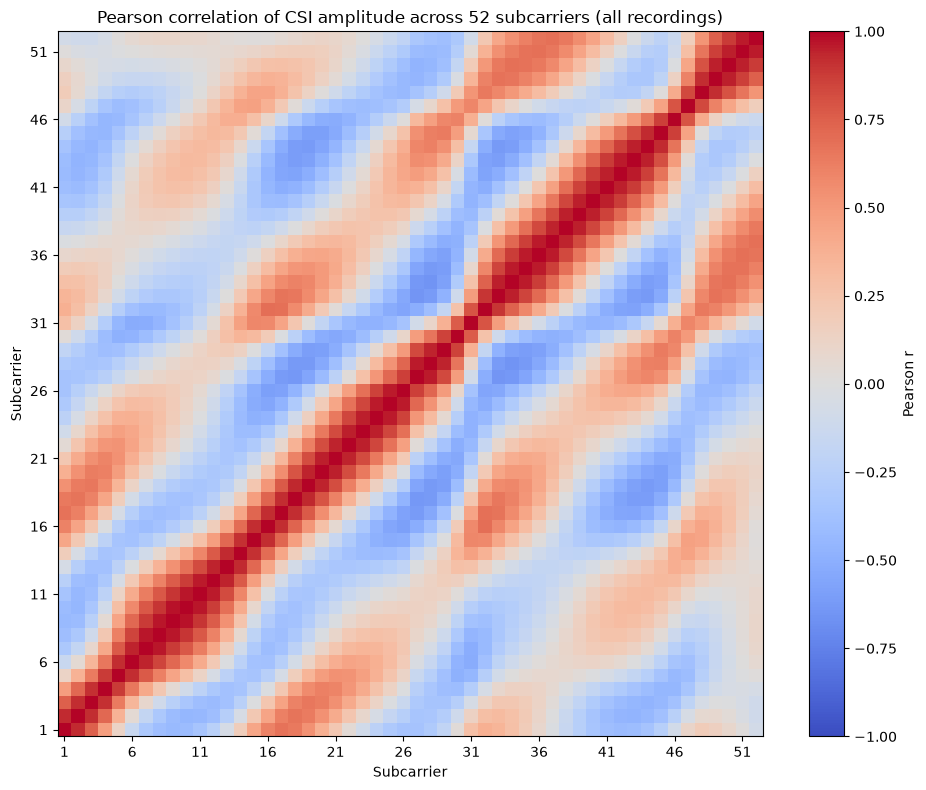

Pooled amplitude matrix shape: (78618, 52); correlation matrix shape: (52, 52)


In [6]:
all_amplitude_rows = np.concatenate([recordings[member]["amplitude"] for member in recordings], axis=0)
correlation = np.corrcoef(all_amplitude_rows, rowvar=False)
if not np.isfinite(correlation).all():
    raise ValueError("Correlation matrix contains non-finite values")
fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1, origin="lower", aspect="equal")
ax.set(title="Pearson correlation of CSI amplitude across 52 subcarriers (all recordings)",
       xlabel="Subcarrier", ylabel="Subcarrier")
ax.set_xticks(np.arange(0, EXPECTED_SUBCARRIERS, 5), np.arange(1, EXPECTED_SUBCARRIERS + 1, 5))
ax.set_yticks(np.arange(0, EXPECTED_SUBCARRIERS, 5), np.arange(1, EXPECTED_SUBCARRIERS + 1, 5))
fig.colorbar(image, ax=ax, label="Pearson r")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "subcarrier_correlation_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()
print(f"Pooled amplitude matrix shape: {all_amplitude_rows.shape}; correlation matrix shape: {correlation.shape}")

## 7. Temporal variability by recording

For each recording, compute standard deviation over time separately for each subcarrier, then summarize those 52 temporal standard deviations by their median and IQR. The heatmap retains subcarrier-level detail; the dot plot shows one session-level median per recording. These are sample-level temporal descriptions, not evidence that occupancy caused variation.

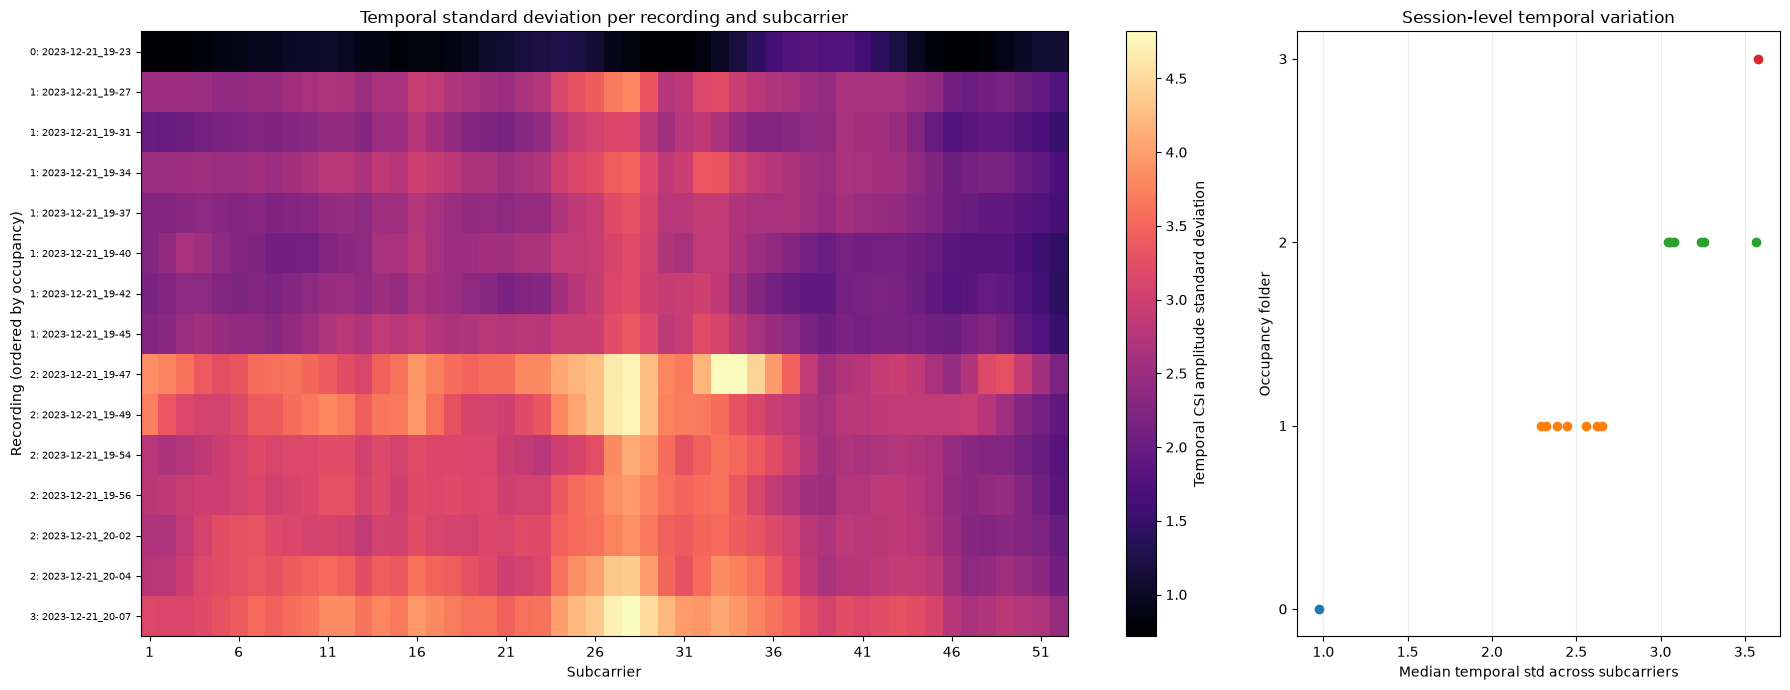

,occupancy,recording,median_subcarrier_temporal_std,q1_subcarrier_temporal_std,q3_subcarrier_temporal_std
0,0,2023-12-21_19-23-53-985_104_1.csv,0.974937,0.820636,1.191753
1,1,2023-12-21_19-27-21-930_104_1.csv,2.623470,2.479683,2.773536
2,1,2023-12-21_19-31-17-706_104_1.csv,2.322063,2.162990,2.588076
3,1,2023-12-21_19-34-42-783_104_1.csv,2.652439,2.497708,2.856290
4,1,2023-12-21_19-37-36-861_104_1.csv,2.445711,2.299332,2.642115
5,1,2023-12-21_19-40-12-110_104_1.csv,2.383004,2.111253,2.648523
6,1,2023-12-21_19-42-28-267_104_1.csv,2.291560,2.117463,2.525198
7,1,2023-12-21_19-45-07-501_104_1.csv,2.555704,2.177055,2.809493
8,2,2023-12-21_19-47-14-669_104_1.csv,3.569021,3.076873,3.824461
9,2,2023-12-21_19-49-37-940_104_1.csv,3.242821,2.897260,3.677422


In [7]:
temporal_rows = []
for row in recording_stats.itertuples(index=False):
    matrix = recordings[row.file]["amplitude"]
    per_subcarrier_std = np.std(matrix, axis=0, ddof=1) if matrix.shape[0] > 1 else np.zeros(matrix.shape[1])
    temporal_rows.append({
        "occupancy": row.occupancy,
        "file": row.file,
        "recording": row.recording,
        "median_subcarrier_temporal_std": float(np.median(per_subcarrier_std)),
        "q1_subcarrier_temporal_std": float(np.quantile(per_subcarrier_std, 0.25)),
        "q3_subcarrier_temporal_std": float(np.quantile(per_subcarrier_std, 0.75)),
        "per_subcarrier_std": per_subcarrier_std,
    })
temporal_stats = pd.DataFrame(temporal_rows).sort_values(["occupancy", "file"]).reset_index(drop=True)
variability_matrix = np.stack(temporal_stats["per_subcarrier_std"].to_list())
fig, (ax_heat, ax_dot) = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [2.4, 1]})
heat = ax_heat.imshow(variability_matrix, aspect="auto", cmap="magma", origin="upper")
ax_heat.set(title="Temporal standard deviation per recording and subcarrier",
            xlabel="Subcarrier", ylabel="Recording (ordered by occupancy)")
ax_heat.set_xticks(np.arange(0, EXPECTED_SUBCARRIERS, 5), np.arange(1, EXPECTED_SUBCARRIERS + 1, 5))
ax_heat.set_yticks(np.arange(len(temporal_stats)), [f"{r.occupancy}: {r.recording[:16]}" for r in temporal_stats.itertuples(index=False)], fontsize=7)
fig.colorbar(heat, ax=ax_heat, label="Temporal CSI amplitude standard deviation")
for occupancy in [0, 1, 2, 3]:
    subset = temporal_stats[temporal_stats.occupancy == occupancy]
    ax_dot.scatter(subset["median_subcarrier_temporal_std"], np.full(len(subset), occupancy), label=f"class {occupancy}")
ax_dot.set(title="Session-level temporal variation", xlabel="Median temporal std across subcarriers", ylabel="Occupancy folder")
ax_dot.set_yticks([0, 1, 2, 3])
ax_dot.grid(axis="x", alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "temporal_variability_by_recording.png", dpi=160, bbox_inches="tight")
plt.show()
display(temporal_stats[["occupancy", "recording", "median_subcarrier_temporal_std", "q1_subcarrier_temporal_std", "q3_subcarrier_temporal_std"]])

## 8. 3D session-representative view

Each class surface uses **every recording** in that class. Each recording is sampled at evenly spaced relative progress points, then session-specific amplitude matrices are averaged with equal session weight. Thus X is normalized session progress rather than absolute time; class 0 and class 3 are each based on one available session. The surface is descriptive and does not replace per-session plots.

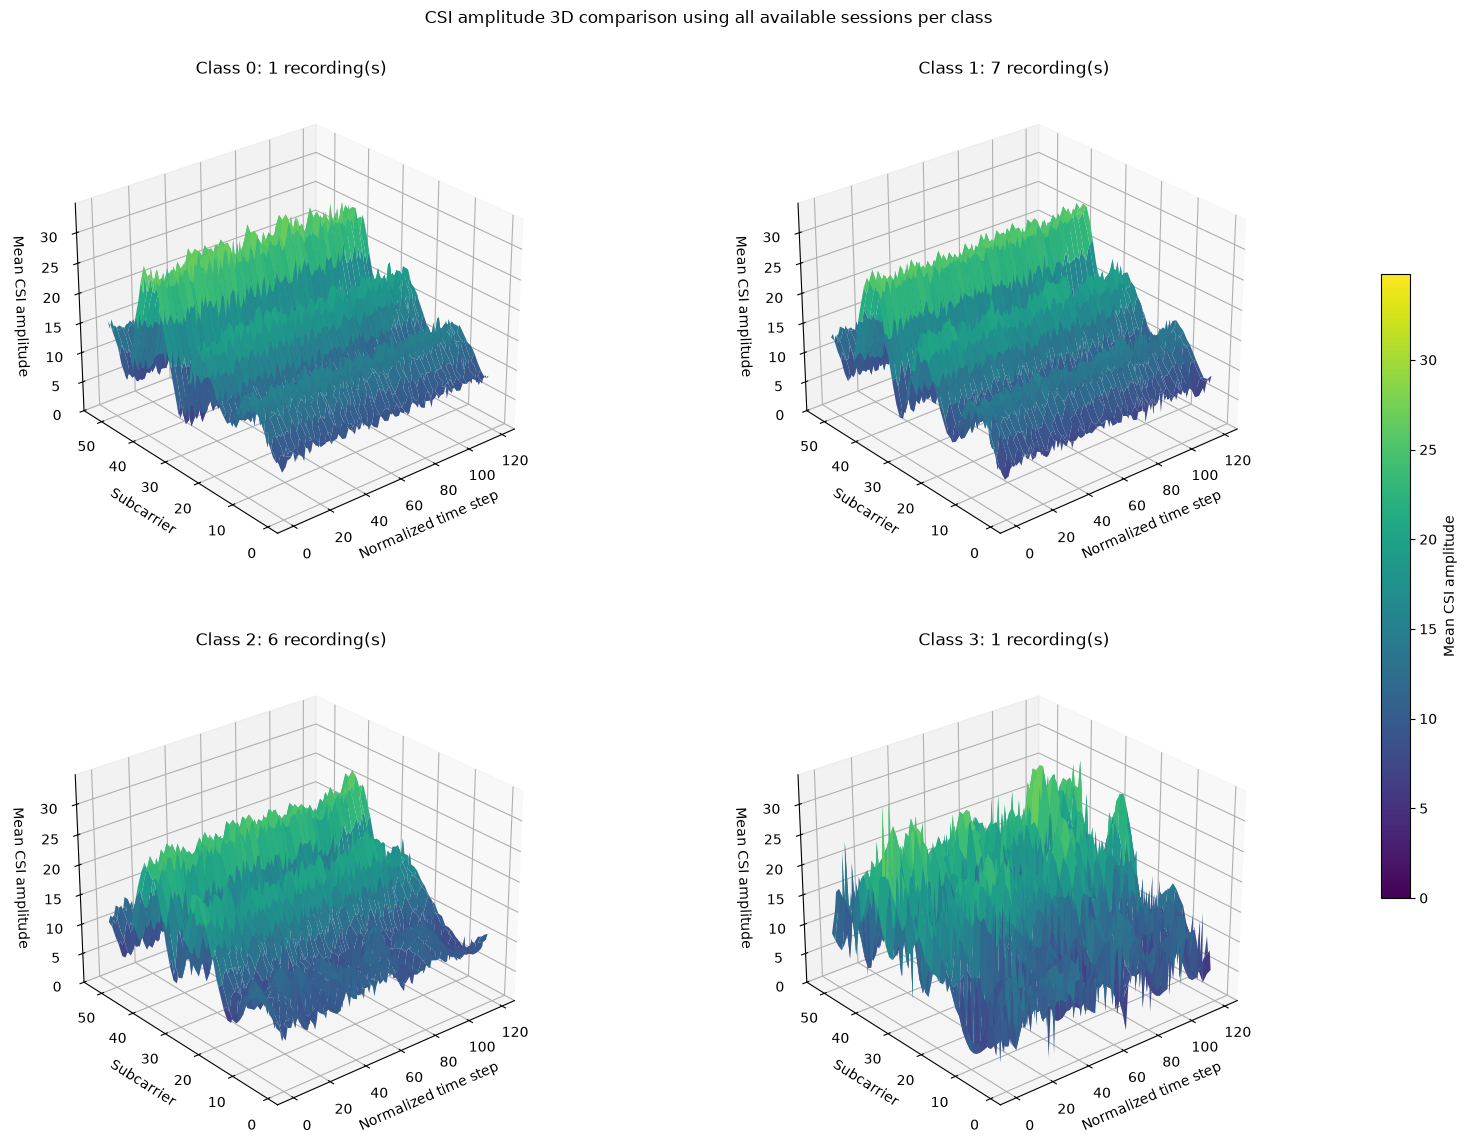

Class session counts: {0: 1, 1: 7, 2: 6, 3: 1}


In [8]:
normalized_steps = 120
progress = np.linspace(0.0, 1.0, normalized_steps)
class_session_mean_surfaces = {}
class_session_spread = {}
for occupancy in [0, 1, 2, 3]:
    members = [member for member in recordings if recordings[member]["occupancy"] == occupancy]
    session_surfaces = []
    for member in members:
        matrix = recordings[member]["amplitude"]
        sample_indices = np.linspace(0, len(matrix) - 1, normalized_steps).round().astype(int)
        session_surfaces.append(matrix[sample_indices, :])
    stacked_sessions = np.stack(session_surfaces)
    class_session_mean_surfaces[occupancy] = stacked_sessions.mean(axis=0)
    class_session_spread[occupancy] = stacked_sessions.std(axis=0, ddof=1) if len(members) > 1 else np.zeros_like(stacked_sessions[0])

z_max = max(float(surface.max()) for surface in class_session_mean_surfaces.values())
x_grid, y_grid = np.meshgrid(np.arange(normalized_steps), np.arange(1, EXPECTED_SUBCARRIERS + 1))
fig = plt.figure(figsize=(16, 12))
last_surface = None
for panel, occupancy in enumerate([0, 1, 2, 3], start=1):
    ax = fig.add_subplot(2, 2, panel, projection="3d")
    z = class_session_mean_surfaces[occupancy].T
    last_surface = ax.plot_surface(x_grid, y_grid, z, cmap="viridis", vmin=0, vmax=z_max,
                                   linewidth=0, antialiased=True)
    count = int((recording_stats["occupancy"] == occupancy).sum())
    ax.set(title=f"Class {occupancy}: {count} recording(s)", xlabel="Normalized time step",
           ylabel="Subcarrier", zlabel="Mean CSI amplitude")
    ax.set_zlim(0, z_max)
    ax.view_init(elev=27, azim=-130)
fig.suptitle("CSI amplitude 3D comparison using all available sessions per class", y=0.98)
fig.subplots_adjust(left=0.03, right=0.90, bottom=0.04, top=0.92, wspace=0.08, hspace=0.18)
colorbar_axis = fig.add_axes([0.92, 0.24, 0.018, 0.52])
fig.colorbar(last_surface, cax=colorbar_axis, label="Mean CSI amplitude")
fig.savefig(OUTPUT_DIR / "csi_3d_all_sessions.png", dpi=160, bbox_inches="tight")
plt.show()
print("Class session counts:", recording_stats.groupby("occupancy").size().to_dict())

## 9. Interpretation, imbalance, and leakage safeguards

The notebook computes descriptive values only. Class/session counts and capture chronology must be considered before later predictive experiments. A random row split would put neighboring CSI rows from the same recording in multiple sets and can inflate apparent generalization. Session grouping is the minimum split unit; class coverage remains impossible to validate for labels with only one session.

In [9]:
row_shares = class_balance["record_share"]
record_shares = class_balance["recording_share"]
print(f"Largest/smallest class row-count ratio: {record_count_by_class.max() / record_count_by_class.min():.2f}:1")
print(f"Largest/smallest class recording-count ratio: {recording_count_by_class.max() / recording_count_by_class.min():.2f}:1")
print("Recommended next experiment: collect multiple independent sessions for every occupancy class, especially 0 and 3; randomize/interleave class order; vary and record room, device placement, activity, and acquisition day.")
print("Recommended future evaluation: group all windows from one source recording/session into a single split; use grouped cross-validation only after each class has enough independent sessions; reserve an acquisition day/room for final external testing when feasible.")
print("No ML training or causal inference was performed in this notebook.")

Largest/smallest class row-count ratio: 7.45:1
Largest/smallest class recording-count ratio: 7.00:1
Recommended next experiment: collect multiple independent sessions for every occupancy class, especially 0 and 3; randomize/interleave class order; vary and record room, device placement, activity, and acquisition day.
Recommended future evaluation: group all windows from one source recording/session into a single split; use grouped cross-validation only after each class has enough independent sessions; reserve an acquisition day/room for final external testing when feasible.
No ML training or causal inference was performed in this notebook.
